USD AAI-520 Final Team Project <p>
October 16, 2026 <p>
<br>
<b>GitHub</b>: seanmcgowanx/multi-agent-financial-analyst <p>
<b>Contributors</b>: Carlo Casella, Ivan Da Silva, Sean McGowan 

# Multi-agent Financial Analyst — Final Deliverable

## 1. Setup

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from multi_agent.config import EVAL_THRESHOLD
from multi_agent.memory import get_lessons
from multi_agent.team import ResearchTeam
from multi_agent.workflows import NewsChain

TICKER = "AAPL"

# One full run feeds every demo below, so the notebook makes one set of API calls.
# A failed first draft appends a lesson to memory/lessons.jsonl (tracked in git).
lessons_before = get_lessons()
team = ResearchTeam()
result = team.run(TICKER)

Coordinator -> Earnings Analyst: Summarize up to four most recent availab...
Coordinator -> Market Analyst: Calculate AAPL closing-price changes ove...
Coordinator -> Market Analyst: Summarize the latest available FRED obse...
Coordinator -> News Analyst: Review recent AAPL news broadly, identif...


## 2. Agent Design and Workflows

Architecture diagram, agent roster (name, role, model), how the lab pattern was extended.

## 3. Agent Functions

### 3.1 Planning

In [2]:
# The lessons injected into the plan prompt, then the steps the coordinator chose.
print(f"Lessons in the plan prompt:\n{lessons_before}\n")
for i, step in enumerate(result["plan"], 1):
    print(f"{i}. [{step['specialist']}] {step['task']}")

Lessons in the plan prompt:
- Plan for traceability: record each source link and date, define the start and end dates for every return calculation, and distinguish financial reporting periods from filing dates.

1. [earnings] Summarize up to four most recent available AAPL quarterly income statements: revenue, margins, net income, and diluted EPS. Compare sequential quarters; make year-over-year comparisons only if the matching prior-year quarters are available, otherwise identify the gap. Include source links and distinguish each reporting period from its SEC filing date.
2. [market] Calculate AAPL closing-price changes over approximately 1, 3, 6, and 12 months through the latest available close. Give the actual start and end observation dates, prices, calculations, and source links. If benchmark closing data are available, compare changes while stating whether observation dates align. Label all price changes as excluding dividends, not total returns.
3. [market] Summarize the latest 

### 3.2 Dynamic tool use

`use_tools` appends each call's steps to the agent's `traces`. Below is each tool-using specialist's most recent loop (`traces[-1]`).

In [3]:
# Each specialist's most recent use_tools loop.
for label in ("earnings", "market"):
    agent = team.specialists[label]
    trace = agent.traces[-1] if agent.traces else []
    print(f"=== {agent.name} ===")
    if not trace:
        print("Not assigned in this plan.")
    for i, step in enumerate(trace, 1):
        if "error" in step:
            print(f"{i}. {step['error']}")
            continue
        print(f"{i}. thought: {step['thought']}")
        print(f"   tool: {step['tool']}({json.dumps(step['args'])})")
        print(f"   result: {str(step['result'])[:300]}")
    print()

=== Earnings Analyst ===
1. thought: I need the quarterly income-statement periods, reported values, and source details to make sequential comparisons and determine whether matching prior-year quarters are available.
   tool: get_financials({"ticker": "AAPL"})
   result: AAPL: 4 latest available quarterly income statements (newest first).
Financial-reporting currency: USD. Amounts are in currency units, not millions; diluted EPS is currency per share.
Quarter ended 2026-06-30: revenue 109,417,000,000.00; gross margin 50.06%; operating margin 32.62%; net income 29,78
2. thought: The income-statement data provides four quarter-end periods and values, but SEC filing dates are needed to distinguish filing dates from reporting periods. I’ll retrieve recent AAPL 10-Q metadata for that distinction.
   tool: get_recent_filings({"ticker": "AAPL", "form_type": "10-Q"})
   result: SEC EDGAR: Apple Inc. (AAPL), CIK 0000320193; up to five recent 10-Q filings (exact form match).
10-Q; filed 2026-07-

### 3.3 Self-reflection

In [4]:
# The evaluator reviews the first draft without seeing the specialists' findings.
first = result["evaluations"][0]
print(f"First draft score: {first['score']}/10 (passing: {EVAL_THRESHOLD})\n")
print(f"Feedback:\n{first['feedback']}")

First draft score: 8/10 (passing: 9)

Feedback:
The report is well organized and meaningfully covers all six requested areas. It distinguishes price changes from total returns, notes the differing price endpoints and observation dates, avoids unsupported causal claims, and clearly identifies missing year-over-year comparisons, benchmark data, valuation information, and limits on the outlook. The conclusions are appropriately conditional. To strengthen support, add publication dates for the iPhone pre-order, broad-market, and smartphone-shipment reports, and provide more precise links for the cited FRED series and SEC filings where available. The Yahoo price history could also identify the exact start and end dates used for each return period. These are documentation gaps rather than clear contradictions; the report appropriately flags several underlying evidence limitations.


### 3.4 Learning across runs

A lesson is written only when a run's first draft fails review, so a run that passes adds nothing. Lessons already in `memory/lessons.jsonl` still go into every plan prompt: compare the plan's tasks with the lessons listed above them.

In [5]:
# Lessons are written only when a run's first draft fails.
new_lessons = set(get_lessons().splitlines()) - set(lessons_before.splitlines())
print("New lessons from the AAPL run:")
print(
    "\n".join(new_lessons)
    or "None (first draft passed, or the lesson was already covered)."
)

# A second run on another ticker reads the updated log in its plan prompt.
print(f"\nLessons in the MSFT plan prompt:\n{get_lessons()}\n")
second_team = ResearchTeam()
second = second_team.run("MSFT")
for i, step in enumerate(second["plan"], 1):
    print(f"{i}. [{step['specialist']}] {step['task']}")

New lessons from the AAPL run:
- Plan a final evidence audit that separates reported facts from interpretation and makes conclusions conditional on the evidence available.

Lessons in the MSFT plan prompt:
- Plan for traceability: record each source link and date, define the start and end dates for every return calculation, and distinguish financial reporting periods from filing dates.
- Plan a final evidence audit that separates reported facts from interpretation and makes conclusions conditional on the evidence available.

Coordinator -> Earnings Analyst: Retrieve up to four recent MSFT quarterl...
Coordinator -> Market Analyst: Calculate MSFT closing-price changes ove...
Coordinator -> News Analyst: Survey recent MSFT news broadly in one p...
Coordinator -> Earnings Analyst: Perform a final evidence audit of the as...
1. [earnings] Retrieve up to four recent MSFT quarterly income statements and recent SEC filing metadata. Record each financial reporting period separately from its fi

## 4. Workflow Patterns

### 4.1 Prompt Chaining

In [6]:
# NewsAnalyst keeps its last chain run; if the plan had no news step, run the chain directly.
chain = team.specialists["news"].last_chain or NewsChain().run(
    TICKER, "Summarize recent news coverage and sentiment."
)
for key in ("raw", "preprocessed", "classified", "extracted", "summary"):
    print(f"=== {key} ===\n{chain[key] or '(skipped: no recent news)'}\n")

=== raw ===
AAPL: latest news from the past 7 days (source: NewsAPI)
2026-10-15 16:21 UTC | Biztoc.com: Apple iPhone Duo available for pre-order Friday
Apple's (AAPL) foldable iPhone Duo is up for pre-order on Friday, just days after the company's market cap topped $5 trillion for the second time.
Apple's most ambitious iPhone yet, the passport-sized Duo is also one of Apple's priciest smartphones to date.
S…
https://biztoc.com/x/82ec697d63bc90f5

2026-10-15 13:28 UTC | PRNewswire: A 20% Drop in Smartphone Shipments Shows Who Wins When Memory Gets Expensive
NEW YORK, Oct. 15, 2026 /PRNewswire/ -- American News Group News Commentary - Global smartphone shipments fell 20% year over year in the third quarter of 2026, the weakest third quarter since 2012, according to preliminary estimates from Counterpoint Research…
https://www.prnewswire.com/news-releases/a-20-drop-in-smartphone-shipments-shows-who-wins-when-memory-gets-expensive-302910152.html

2026-10-15 11:01 UTC | Biztoc.com: Premark

### 4.2 Routing

In [7]:
# Each plan step's label picks the specialist that answers it.
pd.set_option("display.max_colwidth", 150)
display(
    pd.DataFrame(
        {
            "label": [step["specialist"] for step in result["plan"]],
            "task": [step["task"] for step in result["plan"]],
            "findings (start)": [finding[:150] for finding in result["findings"]],
        }
    )
)

,label,task,findings (start)
0,earnings,"Summarize up to four most recent available AAPL quarterly income statements: revenue, margins, net income, and diluted EPS. Compare sequential qua...","**AAPL quarterly income statements** — Source: Yahoo Finance quarterly income statements, https://finance.yahoo.com/quote/AAPL/financials. Amounts..."
1,market,"Calculate AAPL closing-price changes over approximately 1, 3, 6, and 12 months through the latest available close. Give the actual start and end o...",**AAPL closing-price changes through 2026-10-16** (USD; price changes exclude dividends and are not total returns). Calculation: (ending close ÷ s...
2,market,"Summarize the latest available FRED observations and recent direction of the federal funds rate, CPI inflation, unemployment rate, and 10-year Tre...","Latest FRED observations (available through 2026-10-14):\n\n- **Federal funds effective rate (FEDFUNDS):** 3.75% for 2026-09-01, monthly, not seas..."
3,news,"Review recent AAPL news broadly, identifying major developments, contrasting coverage, and overall sentiment. Provide publication dates and links,...","## AAPL news brief — coverage published Oct. 15, 2026\n\n**Overall:** Coverage is mixed. Apple-specific items are upbeat on a reported China AI ap..."


### 4.3 Evaluator-Optimizer

Draft 1: score 8/10, 665 words
Draft 2: score 9/10, 794 words


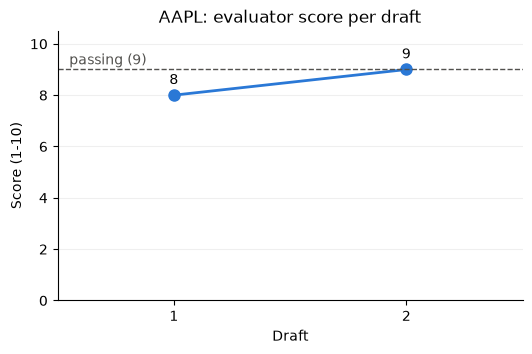

In [8]:
# Every draft is scored; drafts below the threshold are revised, up to MAX_ROUNDS drafts.
scores = [evaluation["score"] for evaluation in result["evaluations"]]
rounds = list(range(1, len(scores) + 1))
for r, draft, score in zip(rounds, result["drafts"], scores):
    print(f"Draft {r}: score {score}/10, {len(draft.split())} words")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(rounds, scores, color="#2a78d6", linewidth=2, marker="o", markersize=8)
ax.axhline(EVAL_THRESHOLD, color="#52514e", linestyle="--", linewidth=1)
ax.text(0.55, EVAL_THRESHOLD + 0.2, f"passing ({EVAL_THRESHOLD})", color="#52514e")
for r, score in zip(rounds, scores):
    ax.annotate(
        str(score), (r, score), textcoords="offset points", xytext=(0, 8), ha="center"
    )
ax.set(
    title=f"{TICKER}: evaluator score per draft",
    xlabel="Draft",
    ylabel="Score (1-10)",
    xticks=rounds,
    xlim=(0.5, len(rounds) + 0.5),
    ylim=(0, 10.5),
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
plt.show()

## 5. End-to-End Run

In [9]:
display(Markdown(result["report"]))

# AAPL Investment Research Report
*As of October 16, 2026. Based solely on the supplied findings.*

## Summary

Apple’s latest supplied quarter showed nearly flat revenue but modest improvements in margins, net income and diluted earnings per share (EPS) from the preceding quarter. Its share price rose across each supplied measurement period, including 37.91% over 12 months. The outlook is mixed: Apple-specific news is encouraging but unverified, while a reported smartphone-shipment decline and a 5.19% 10-year Treasury yield present risks. The findings do not provide enough information to assess valuation or estimate a price target.

## Financials

The [Yahoo Finance quarterly income statements](https://finance.yahoo.com/quote/AAPL/financials) provide the following figures. Dollar amounts are in billions except EPS.

| Yahoo quarter ended | Revenue | Gross margin | Operating margin | Net income | Diluted EPS |
|---|---:|---:|---:|---:|---:|
| 2025-09-30 | $102.466 | 47.18% | 31.65% | $27.466 | $1.85 |
| 2025-12-31 | $143.756 | 48.16% | 35.37% | $42.097 | $2.84 |
| 2026-03-31 | $111.184 | 49.27% | 32.28% | $29.578 | $2.01 |
| 2026-06-30 | $109.417 | 50.06% | 32.62% | $29.789 | $2.02 |

From March to June 2026, revenue fell **1.6%**, while gross margin rose **0.79 percentage points**, operating margin rose **0.34 points**, net income rose **0.7%**, and EPS increased by **$0.01**. The much larger December-quarter results make sequential revenue and earnings comparisons sensitive to the quarter chosen. Matching prior-year income statements were not supplied, so **year-over-year financial growth cannot be established**.

The corresponding SEC filing metadata identifies report periods that differ from Yahoo’s quarter-end dates: the [10-Q filed July 31, 2026](https://www.sec.gov/Archives/edgar/data/320193/000032019326000020/aapl-20260627.htm) has a June 27 report period; the [10-Q filed May 1, 2026](https://www.sec.gov/Archives/edgar/data/320193/000032019326000013/aapl-20260328.htm) has a March 28 report period; and the [10-Q filed January 30, 2026](https://www.sec.gov/Archives/edgar/data/320193/000032019326000006/aapl-20251227.htm) has a December 27, 2025 report period. Filing contents were not reviewed, and matching SEC filing metadata was not available for Yahoo’s September 2025 period.

## News & Sentiment

A [premarket roundup published October 15 at 11:01 UTC](https://biztoc.com/x/de072c88a35837ef) reported a rise in Apple shares following a report that Apple Intelligence had been approved in China. The supplied summary did not verify the approval or quantify the share move. A separate [report published October 15 at 16:21 UTC](https://biztoc.com/x/82ec697d63bc90f5) said the iPhone Duo would become available for pre-order Friday, without supplying a price or specifications.

A [report published October 15 at 00:54 UTC](https://macdailynews.com/2026/10/14/apple-shares-hit-new-all-time-closing-high-34/) said Apple shares had reached a record closing high but lacked a closing price and session date. A [broad-market decline report published October 15 at 00:56 UTC](https://biztoc.com/x/4a6a64ad65624482) did not specify an AAPL move; the summaries do not establish that the reports concern the same session. Industry sentiment is less favorable: a [PRNewswire item published October 15 at 13:28 UTC](https://www.prnewswire.com/news-releases/a-20-drop-in-smartphone-shipments-shows-who-wins-when-memory-gets-expensive-302910152.html) reported a 20% year-over-year drop in global smartphone shipments, but the supplied summary did not identify its data source or quarter. None of these summaries establishes what caused an AAPL price move.

## Market

AAPL’s supplied [Yahoo closing-price histories](https://finance.yahoo.com/quote/AAPL/history) show the following changes. Each calculation uses the start and end closes returned for that period.

| Approx. horizon | Start date and close | End date and close | Price change |
|---|---|---|---:|
| 1 month | 2026-09-16: $332.41 | 2026-10-16: $341.26 | **+2.66%** |
| 3 months | 2026-07-16: $333.26 | 2026-10-16: $341.28 | **+2.41%** |
| 6 months | 2026-04-16: $263.40 | 2026-10-16: $341.26 | **+29.57%** |
| 12 months | 2025-10-16: $247.45 | 2026-10-16: $341.27 | **+37.91%** |

These are **price changes, not total returns**; dividends are excluded. The histories give three slightly different October 16 closes—$341.26, $341.27 and $341.28—so the endpoint discrepancy remains unresolved. No benchmark data was supplied for a relative-performance comparison.

The latest supplied FRED readings were a **3.75%** [effective federal funds rate](https://fred.stlouisfed.org/series/FEDFUNDS), approximately **3.72%** year-over-year inflation calculated from seasonally adjusted [CPI index levels](https://fred.stlouisfed.org/series/CPIAUCSL), and **4.2%** [unemployment](https://fred.stlouisfed.org/series/UNRATE), all for September 2026. The [10-year Treasury yield](https://fred.stlouisfed.org/series/DGS10) was **5.19%** on October 14. The first three are monthly observations and the yield is a daily observation; they should not be treated as a single-day snapshot.

## Risks

Key risks in the supplied findings are the reported smartphone-market weakness and uncertainty around the China AI and product-launch headlines. A high 10-year Treasury yield may also weigh on equity valuations, though the findings do not measure its effect on AAPL. The data lacks matching prior-year financial quarters, a benchmark, reviewed SEC filing contents, and the valuation or cash-flow information needed for a fuller investment assessment.

## Outlook

Improving margins in the latest supplied quarter and positive longer-horizon share-price performance support a constructive case. That case remains conditional: investors would need confirmation of the reported Apple-specific developments and evidence of how Apple performs against the reported industry weakness. **The supplied information does not justify a price target or a definitive buy or sell conclusion.**

Like the lab's `show_team_status`, this counts the tasks each agent recorded in memory during the AAPL run: one per routed plan step for the specialists, plan, synthesize and each revision for the coordinator, and one score per draft for the evaluator.

In [10]:
team.show_team_status()


TEAM STATUS
  Coordinator (financial research coordinator): 3 tasks completed
  Earnings Analyst (earnings research specialist): 1 tasks completed
  Market Analyst (market research specialist): 2 tasks completed
  News Analyst (financial news research specialist): 1 tasks completed
  Evaluator (financial report reviewer): 2 tasks completed


## 6. Evaluation and Iteration

Scores across tickers/runs (visualization), what changed, limitations.